# NeuroScan — Data Collection & Preprocessing

**Role 1 deliverable for the NeuroScan brain tumor MRI capstone.**

This notebook is self-contained: run it top to bottom on any machine with Python 3.9+ and
an internet connection, and it will install what it needs, fetch the dataset from Kaggle,
verify every image, and build `data/processed/manifest.csv` — the file the other three roles
(Model Development, Evaluation, Deployment) build on.

**Output for the rest of the team:** `data/processed/manifest.csv`, plus the raw images
under `data/raw/`. Each teammate who runs this notebook gets their own local copy — nothing
here depends on anyone else's machine or setup.

**Where to run it from:** wherever you like — the first code cell prints the exact folder
`data/` will be created in (wherever you launch this notebook from), so you can confirm
before anything downloads.


## 1. Install dependencies

Only light, general-purpose packages — no deep learning libraries needed for this step. Safe to re-run; already-installed packages are skipped.

In [ ]:
%pip install -q kagglehub pillow pandas numpy

In [ ]:
import os
import sys
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import PIL
from PIL import Image, UnidentifiedImageError
#KGAT_c3990b4b1a0feedee20aca960dab6307
print("Python", sys.version.split()[0])
print("kagglehub", kagglehub.__version__)
print("pandas", pd.__version__)
print("numpy", np.__version__)
print("Pillow", PIL.__version__)


Python 3.12.13
kagglehub 1.0.2
pandas 2.2.2
numpy 2.0.2
Pillow 11.3.0


## 2. Kaggle API credentials

Downloading the dataset needs a free Kaggle account and an API token.

1. Sign in at [kaggle.com](https://www.kaggle.com), go to **Settings → API**, and click
   **Create New Token**. This downloads a `kaggle.json` file.
2. Either:
   - **Recommended (persists across runs):** place that file at `~/.kaggle/kaggle.json`
     (Mac/Linux) or `C:\Users\<you>\.kaggle\kaggle.json` (Windows), or
   - **No setup needed:** just run the next cell. If no credentials are found on your
     machine, it will prompt you right here for your Kaggle username and API key —
     nothing is written to disk unless you've already saved `kaggle.json` yourself.


In [ ]:
from kagglehub.config import get_kaggle_credentials

if get_kaggle_credentials() is None:
    print("No Kaggle credentials found on this machine.")
    print("Get a token from https://www.kaggle.com/settings/api, then enter it below.")
    kagglehub.login()
else:
    print("Kaggle credentials found — continuing.")


No Kaggle credentials found on this machine.
Get a token from https://www.kaggle.com/settings/api, then enter it below.


Kaggle credentials set.
Kaggle credentials successfully validated.


## 3. Download the dataset

[`masoudnickparvar/brain-tumor-mri-dataset`](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset)
(~165 MB) — 7,200 MRI images across 4 classes: `glioma`, `meningioma`, `notumor`, `pituitary`.
Pre-split by the dataset author into `Training/` and `Testing/` folders. Chosen for this
capstone specifically because it's small enough to download and process on a laptop with no
GPU. Cite the dataset link above in the final report.

`kagglehub` caches the download, so re-running this cell later won't re-download unless the
cache is cleared.


In [ ]:
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
os.environ["KAGGLEHUB_CACHE"] = str(RAW_DIR)

dataset_path = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset"))

print("Running from:", BASE_DIR)
print("Dataset downloaded to:", dataset_path)
print("Training folder:", (dataset_path / "Training").exists())
print("Testing folder:", (dataset_path / "Testing").exists())


Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Running from: /content
Dataset downloaded to: /kaggle/input/brain-tumor-mri-dataset
Training folder: True
Testing folder: True


## 4. Verify data integrity

Opens every image to confirm it isn't corrupted, and records its class, dimensions, and
color mode. Any unreadable file is reported below rather than silently dropped.


In [ ]:
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

def scan_split(split_dir: Path, split_name: str) -> pd.DataFrame:
    records = []
    corrupt = []
    for cls in CLASSES:
        for img_path in sorted((split_dir / cls).iterdir()):
            if not img_path.is_file():
                continue
            try:
                with Image.open(img_path) as im:
                    im.verify()
                with Image.open(img_path) as im:
                    width, height = im.size
                    mode = im.mode
            except (UnidentifiedImageError, OSError) as e:
                corrupt.append((str(img_path), str(e)))
                continue
            records.append({
                "path": str(img_path.relative_to(dataset_path)),
                "class": cls,
                "width": width,
                "height": height,
                "mode": mode,
                "source_split": split_name,
            })
    if corrupt:
        print(f"{len(corrupt)} corrupt file(s) in {split_name}:")
        for path, err in corrupt:
            print(" -", path, err)
    return pd.DataFrame.from_records(records)


train_df = scan_split(dataset_path / "Training", "train_raw")
test_df = scan_split(dataset_path / "Testing", "test")

print("Training (pre-split) class counts:")
print(train_df["class"].value_counts())
print()
print("Testing class counts:")
print(test_df["class"].value_counts())
print()
all_dims = pd.concat([train_df[["width", "height"]], test_df[["width", "height"]]]).drop_duplicates()
all_modes = sorted(set(train_df["mode"]).union(test_df["mode"]))
print("Distinct image dimensions:", len(all_dims))
print("Distinct color modes:", all_modes)


Training (pre-split) class counts:
class
glioma        1400
meningioma    1400
notumor       1400
pituitary     1400
Name: count, dtype: int64

Testing class counts:
class
glioma        400
meningioma    400
notumor       400
pituitary     400
Name: count, dtype: int64

Distinct image dimensions: 447
Distinct color modes: ['L', 'P', 'RGB', 'RGBA']


**What this means for the team:** if the cell above reports 0 corrupt files and 4 balanced
class counts, the raw data is clean. The dimensions and color modes are *not* uniform across
images — Role 2 (Model Development) needs a resize + `.convert("RGB")` step in its
`torchvision.transforms` pipeline before batching; don't assume images arrive pre-normalized.


## 5. Build the train/val/test manifest

The dataset author's `Testing/` folder is kept exactly as shipped (untouched) so held-out
results stay comparable to published baselines. A validation set is carved out of `Training/`
only, stratified per class with a fixed random seed so it's reproducible run to run.


In [ ]:
SEED = 42
VAL_FRACTION = 0.15


def stratified_split(df: pd.DataFrame, val_fraction: float, seed: int):
    train_parts, val_parts = [], []
    for _, group in df.groupby("class"):
        shuffled = group.sample(frac=1.0, random_state=seed)
        n_val = int(len(shuffled) * val_fraction)
        val_parts.append(shuffled.iloc[:n_val])
        train_parts.append(shuffled.iloc[n_val:])
    return pd.concat(train_parts).reset_index(drop=True), pd.concat(val_parts).reset_index(drop=True)


train_final, val_final = stratified_split(train_df, VAL_FRACTION, SEED)
train_final["split"] = "train"
val_final["split"] = "val"
test_final = test_df.copy()
test_final["split"] = "test"

manifest = pd.concat([train_final, val_final, test_final], ignore_index=True)
manifest = manifest.drop(columns=["source_split"])

manifest_path = PROCESSED_DIR / "manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Manifest written to:", manifest_path)
print()
print(manifest["split"].value_counts())
print()
print(pd.crosstab(manifest["class"], manifest["split"]))


Manifest written to: /content/data/processed/manifest.csv

split
train    4760
test     1600
val       840
Name: count, dtype: int64

split       test  train  val
class                       
glioma       400   1190  210
meningioma   400   1190  210
notumor      400   1190  210
pituitary    400   1190  210


## 6. Handoff notes for the rest of the team

- **File to build on:** `data/processed/manifest.csv` — columns `path, class, width, height,
  mode, split`. `path` is relative to wherever you ran this notebook from; load images with
  `Image.open(BASE_DIR / row["path"])`.
- **Load it directly:** `pd.read_csv("data/processed/manifest.csv")`.
- **Classes are balanced** (1,400/class in `Training/`, 400/class in `Testing/`) — accuracy is
  a fair headline metric, but Role 3 should still report per-class precision/recall/F1, since
  glioma and meningioma are the more clinically-confusable pair.
- **Images are not uniform** in size or color mode — resize + `.convert("RGB")` before
  feeding a model.
- **Reproducible:** re-running this whole notebook regenerates the same manifest (fixed
  `SEED = 42`); `kagglehub` won't re-download if the dataset is already cached locally.
- **Don't commit `data/raw/` or `data/processed/` to git** if this project is shared via a
  repo — they're regenerated by this notebook and add ~165 MB of images to history for no
  benefit; everyone can just re-run this notebook to get their own copy.


---
# NeuroScan — Model Development (Role 2)

**Role 2 deliverable for the NeuroScan brain tumor MRI capstone.**

This notebook reads `data/processed/manifest.csv` generated by Role 1, builds PyTorch DataLoaders with medical-grade data augmentations, and trains baseline/transfer-learning deep learning architectures (Custom CNN, ResNet-50, DenseNet-121).

**Outputs for the team:**
- `models/best_custom_cnn.pth`
- `models/best_resnet50.pth`
- `models/best_densenet121.pth`
- Training/Validation history logs for Role 3 (Evaluation).


## 1: Environment Setup & Global Reproducibility

We import all required libraries (PyTorch, Torchvision, Pandas, NumPy, PIL) and define a global seed function to enforce deterministic behavior across CPU and GPU operations.

Neural network weights are initialized randomly, and data shuffling uses pseudo-random number generators. Setting a fixed random seed (e.g., `SEED = 42`) guarantees that any teammate or grader running this notebook will get identical train/val splits, weight initializations, and performance metrics.

In [ ]:
import os
print(os.getcwd())

/content


In [ ]:
#import os
#print(os.listdir())

In [ ]:
#pip uninstall torch torchvision torchaudio -y

In [ ]:
#pip cache purge

In [ ]:
#pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

In [ ]:
%pip install -q torch torchvision

# Import standard system and OS interaction modules
import os  # Provides functions for creating directories and handling file paths
import random  # Python's built-in pseudo-random number generator
from pathlib import Path  # Object-oriented filesystem path manipulation

# Import core scientific computing and data analysis libraries
import numpy as np  # Fundamental package for linear algebra and array operations
import pandas as pd  # Data manipulation library used to read and filter manifest.csv
from PIL import Image  # Python Imaging Library for loading and converting MRI image files

# Import core PyTorch libraries for deep learning
import torch  # Core PyTorch tensor library and GPU execution engine
import torch.nn as nn  # Neural network building blocks (layers, loss functions)
from torch.utils.data import Dataset, DataLoader  # Utilities for building custom datasets and mini-batch iterators

# Import torchvision utilities for computer vision backbones and image transformations
import torchvision.transforms as T  # Module containing standard image transformation pipelines
from torchvision import models  # Pre-trained deep learning architectures (ResNet, DenseNet)

# Define fixed global seed for reproducibility across all libraries
SEED = 42  # Standard seed value ensuring identical results on every execution

# Define a function to enforce deterministic execution across hardware and software frameworks
def seed_everything(seed=42):
    # Set the seed for Python's built-in random module
    random.seed(seed)
    # Set the seed for Python's environment variable random seed
    os.environ["PYTHONHASHSEED"] = str(seed)
    # Set the seed for NumPy array generation
    np.random.seed(seed)
    # Set the seed for CPU-based PyTorch tensor operations
    torch.manual_seed(seed)
    # Set the seed for GPU-based PyTorch tensor operations across all CUDA devices
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    # Force cuDNN algorithms to be deterministic (reproducible)
    torch.backends.cudnn.deterministic = True
    # Disable automatic cuDNN benchmark searching to ensure exact algorithm selection
    torch.backends.cudnn.benchmark = False

# Execute the seed setting function
seed_everything(SEED)

# Detect and configure the optimal execution hardware device (CUDA GPU if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Print execution environment diagnostics
print(f"PyTorch Version: {torch.__version__}")
print(f"Global Random Seed set to: {SEED}")
print(f"Active Hardware Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

PyTorch Version: 2.11.0+cu128
Global Random Seed set to: 42
Active Hardware Device: cuda
GPU Model: Tesla T4


## Custom PyTorch Dataset & Data Augmentations

We constructed a custom `BrainTumorDataset` class that inherits from `torch.utils.data.Dataset`. It reads image paths from `manifest.csv`, converts every image to 3-channel RGB, maps string class labels to integer IDs (`glioma: 0`, `meningioma: 1`, `notumor: 2`, `pituitary: 3`), and applies specified `torchvision` transforms.

### We do this because:
- **`__len__` and `__getitem__` methods:** PyTorch requires these methods so `DataLoader` can query the total number of samples and fetch individual image-label tensor pairs on demand.
- **Data Augmentation:** Training transforms include `RandomHorizontalFlip` and `RandomRotation(degrees=15)` to expose the model to variations in patient orientation. Validation/test transforms omit augmentations to ensure objective scoring.

In [ ]:
# Define mapping from string target classes to explicit integer class indices
CLASS_TO_IDX = {
    "glioma": 0,       # Map class 'glioma' to integer index 0
    "meningioma": 1,   # Map class 'meningioma' to integer index 1
    "notumor": 2,      # Map class 'notumor' to integer index 2
    "pituitary": 3     # Map class 'pituitary' to integer index 3
}

# Define reverse mapping from integer index back to human-readable string class name
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}

# Define standardized input resolution for pre-trained ImageNet backbones
IMAGE_SIZE = (224, 224)  # Standard height x width expected by ResNet and DenseNet

# Define ImageNet mean and standard deviation for channel normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]  # Per-channel mean computed across ImageNet dataset
IMAGENET_STD = [0.229, 0.224, 0.225]   # Per-channel standard deviation computed across ImageNet dataset

# Define image transformation pipeline for the TRAINING dataset split
train_transforms = T.Compose([
    T.Resize(IMAGE_SIZE),  # Resize non-uniform raw images to standard 224x224 pixels
    T.RandomHorizontalFlip(p=0.5),  # Horizontally mirror 50% of images to simulate anatomical symmetry
    T.RandomRotation(degrees=15),  # Slightly rotate images by +/- 15 degrees to simulate patient position shifts
    T.ToTensor(),  # Convert PIL Image object (0-255 values) to PyTorch FloatTensor (0.0-1.0 values)
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)  # Standardize pixel distributions to ImageNet scales
])

# Define image transformation pipeline for VALIDATION and TESTING dataset splits
val_test_transforms = T.Compose([
    T.Resize(IMAGE_SIZE),  # Resize input images to standard 224x224 pixels (no augmentations added)
    T.ToTensor(),  # Convert PIL Image object (0-255 values) to PyTorch FloatTensor (0.0-1.0 values)
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)  # Standardize pixel distributions to ImageNet scales
])

# Define custom Dataset class inheriting from PyTorch's abstract Dataset module
class BrainTumorDataset(Dataset):
    # Constructor method executed upon dataset object instantiation
    def __init__(self, df: pd.DataFrame, base_dir: Path, transform=None):
        # Store the filtered DataFrame slice (train, val, or test rows)
        self.df = df.reset_index(drop=True)
        # Store the base directory path of the project workspace
        self.base_dir = Path(base_dir)
        # Store the assigned transformation pipeline (train_transforms or val_test_transforms)
        self.transform = transform

    # Mandatory PyTorch dataset method returning total sample count
    def __len__(self):
        # Return total number of rows present in the input DataFrame slice
        return len(self.df)

    # Mandatory PyTorch dataset method returning single (image_tensor, target_label) pair at requested index
    def __getitem__(self, idx: int):
        # Extract row corresponding to index `idx`
        row = self.df.iloc[idx]
        # Construct full absolute image file path combining base directory and relative manifest path
        img_path = self.base_dir / row["path"]

        # Load image file from disk and force conversion to 3-channel RGB color space
        with Image.open(img_path) as img:
            image = img.convert("RGB")

        # Convert string class label to integer target label using dictionary mapping
        label_str = row["class"]
        label = CLASS_TO_IDX[label_str]

        # Apply transformation pipeline if a valid transform object was passed
        if self.transform is not None:
            image = self.transform(image)

        # Return processed PyTorch image tensor and integer label as a tuple
        return image, label

print("Custom Dataset class and Transformation Pipelines created successfully!")

Custom Dataset class and Transformation Pipelines created successfully!


## Instantiate DataLoaders & Verify Batch Integrity

We load `data/processed/manifest.csv` generated in Role 1, slice it by `split` column (`train`, `val`, `test`), instantiate our `BrainTumorDataset` objects, and wrap them in PyTorch `DataLoader` instances with a batch size of 32. Finally, we iterate over a single mini-batch to verify tensor shapes and class indices.

`DataLoader` manages automatic parallel batching, data shuffling, and memory loading. Verifying batch tensor dimensions (e.g., `torch.Size([32, 3, 224, 224])`) before passing them to neural network architectures ensures that shape mismatches or corrupt file exceptions are caught early.

In [ ]:
# Define workspace path variables
BASE_DIR = Path.cwd()  # Capture current working directory path
DATA_DIR = BASE_DIR / "data"  # Locate 'data' directory
MANIFEST_PATH = DATA_DIR / "processed" / "manifest.csv"  # Locate manifest.csv path generated by Role 1

# Check if manifest.csv exists before attempting to load
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Manifest not found at {MANIFEST_PATH}! Please run Notebook 01 (Role 1) first to generate manifest.csv."
    )

# Load master dataset manifest into Pandas DataFrame
manifest_df = pd.read_csv(MANIFEST_PATH)
print(f"Loaded master manifest successfully. Total entries: {len(manifest_df)}")

# Separate DataFrame into distinct train, validation, and test subsets based on 'split' column
train_df = manifest_df[manifest_df["split"] == "train"].copy()  # Extract training set rows (4,760 samples)
val_df = manifest_df[manifest_df["split"] == "val"].copy()      # Extract validation set rows (840 samples)
test_df = manifest_df[manifest_df["split"] == "test"].copy()    # Extract testing set rows (1,600 samples)

# Instantiate custom PyTorch Dataset objects for each split
train_dataset = BrainTumorDataset(df=train_df, base_dir=dataset_path, transform=train_transforms)
val_dataset = BrainTumorDataset(df=val_df, base_dir=dataset_path, transform=val_test_transforms)
test_dataset = BrainTumorDataset(df=test_df, base_dir=dataset_path, transform=val_test_transforms)

# Define standard batch size hyperparameter for model training
BATCH_SIZE = 32  # Load images in mini-batches of 32 samples

# Instantiate PyTorch DataLoader instances for mini-batching and parallel loading
train_loader = DataLoader(
    dataset=train_dataset,  # Training dataset instance
    batch_size=BATCH_SIZE,  # Mini-batch size
    shuffle=True,  # Shuffle samples every epoch to randomize gradient updates
    num_workers=0,  # Use 2 parallel worker processes for data loading
    pin_memory=True if torch.cuda.is_available() else False  # Speed up host-to-device transfer if GPU is active
)

val_loader = DataLoader(
    dataset=val_dataset,  # Validation dataset instance
    batch_size=BATCH_SIZE,  # Mini-batch size
    shuffle=False,  # Do not shuffle validation set for consistent evaluation
    num_workers=0,  # Use 2 parallel worker processes
    pin_memory=True if torch.cuda.is_available() else False  # Pin memory if GPU available
)

test_loader = DataLoader(
    dataset=test_dataset,  # Testing dataset instance
    batch_size=BATCH_SIZE,  # Mini-batch size
    shuffle=False,  # Do not shuffle test set
    num_workers=0,  # Use 2 parallel worker processes
    pin_memory=True if torch.cuda.is_available() else False  # Pin memory if GPU available
)

# Fetch a single mini-batch from train_loader to verify shapes and types
sample_images, sample_labels = next(iter(train_loader))

# Display batch verification diagnostics
print("\n--- DataLoader Sanity Check ---")
print(f"Training Batches: {len(train_loader)} (Total samples: {len(train_dataset)})")
print(f"Validation Batches: {len(val_loader)} (Total samples: {len(val_dataset)})")
print(f"Testing Batches: {len(test_loader)} (Total samples: {len(test_dataset)})")
print(f"Sample Batch Image Tensor Shape: {sample_images.shape} -> [Batch Size, Channels, Height, Width]")
print(f"Sample Batch Label Tensor Shape: {sample_labels.shape} -> [Batch Size]")
print(f"Sample Batch Target Labels: {sample_labels.tolist()[:10]}")


Loaded master manifest successfully. Total entries: 7200

--- DataLoader Sanity Check ---
Training Batches: 149 (Total samples: 4760)
Validation Batches: 27 (Total samples: 840)
Testing Batches: 50 (Total samples: 1600)
Sample Batch Image Tensor Shape: torch.Size([32, 3, 224, 224]) -> [Batch Size, Channels, Height, Width]
Sample Batch Label Tensor Shape: torch.Size([32]) -> [Batch Size]
Sample Batch Target Labels: [0, 1, 2, 2, 1, 0, 1, 1, 0, 0]


### Output Interpretation:
- **Manifest Loaded:** Confirms that `manifest.csv` generated in Role 1 was successfully read with 7,200 total samples.
- **Data Splits:** Confirms exact sample partitioning: **4,760 train**, **840 validation**, and **1,600 test** samples.
- **Batch Shape `[32, 3, 224, 224]`:** Indicates that mini-batches contain 32 images, converted to 3 RGB channels, resized to $224 \times 224$ pixels, and converted to PyTorch float tensors.
- **Labels:** Integers `0, 1, 2, 3` map directly to `glioma`, `meningioma`, `notumor`, and `pituitary`.

---
## 2: Custom CNN Architecture & Baseline Training

**Objective:** Design and train a lightweight 4-stage Convolutional Neural Network from scratch to serve as our empirical baseline before implementing transfer learning models.

**Architecture Overview:**
- **4 Convolutional Blocks:** Exponential feature expansion ($3 \rightarrow 32 \rightarrow 64 \rightarrow 128 \rightarrow 256$ channels).
- **Batch Normalization & ReLU:** Applied after each $3 \times 3$ convolution to stabilize training gradients.
- **Max Pooling:** $2 \times 2$ spatial downsampling across blocks ($224 \times 224 \rightarrow 14 \times 14$).
- **Classifier Head:** Dropout ($p=0.4$) for regularization, bridging into a fully connected layer predicting 4 class logits.

In [ ]:
import gc
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [ ]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path

# Create directory to save model weights
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Define Custom CNN Architecture
class CustomCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(CustomCNN, self).__init__()

        self.features = nn.Sequential(
            # Block 1: 32 channels
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # Output: [32, 32, 112, 112]

            # Block 2: 64 channels
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # Output: [32, 64, 56, 56]

            # Block 3: 128 channels
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # Output: [32, 128, 28, 28]

            # Block 4: 256 channels
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)  # Output: [32, 256, 14, 14]
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)), # Global Average Pooling -> [32, 256, 1, 1]
            nn.Flatten(),
            nn.Dropout(p=0.4),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Instantiate model
custom_model = CustomCNN(num_classes=4).to(device)

# Define Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(custom_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# Training Loop Function with Best Weight Checkpointing
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=10, save_path="models/best_custom_cnn.pth"):
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_loss = float('inf')

    print(f"--- Starting Training: {save_path.name} ---")
    start_time = time.time()

    for epoch in range(num_epochs):
        epoch_start = time.time()

        # Training Phase
        model.train()
        running_loss, running_corrects, total_samples = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * images.size(0)
            running_corrects += torch.sum(preds == labels.data).item()
            total_samples += images.size(0)

        epoch_train_loss = running_loss / total_samples
        epoch_train_acc = running_corrects / total_samples

        # Validation Phase
        model.eval()
        val_running_loss, val_running_corrects, val_total_samples = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                _, preds = torch.max(outputs, 1)
                val_running_loss += loss.item() * images.size(0)
                val_running_corrects += torch.sum(preds == labels.data).item()
                val_total_samples += images.size(0)

        epoch_val_loss = val_running_loss / val_total_samples
        epoch_val_acc = val_running_corrects / val_total_samples

        # Learning rate scheduling
        scheduler.step(epoch_val_loss)

        # Store metrics
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)

        epoch_time = time.time() - epoch_start

        # Save best model checkpoint
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            torch.save(model.state_dict(), save_path)
            saved_str = " -> Best Model Saved!"
        else:
            saved_str = ""

        print(f"Epoch [{epoch+1:02d}/{num_epochs:02d}] ({epoch_time:.1f}s) | "
              f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc*100:.2f}% | "
              f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc*100:.2f}%{saved_str}")

    total_time = time.time() - start_time
    print(f"\n--- Training Complete in {total_time/60:.2f} mins | Best Val Loss: {best_val_loss:.4f} ---")
    return history

# Execute training for 10 epochs
custom_cnn_history = train_model(
    model=custom_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=10,
    save_path=MODELS_DIR / "best_custom_cnn.pth"
)


--- Starting Training: best_custom_cnn.pth ---
Epoch [01/10] (53.6s) | Train Loss: 0.8358, Train Acc: 66.64% | Val Loss: 1.2771, Val Acc: 40.95% -> Best Model Saved!
Epoch [02/10] (44.5s) | Train Loss: 0.6979, Train Acc: 72.48% | Val Loss: 0.7133, Val Acc: 72.26% -> Best Model Saved!
Epoch [03/10] (41.8s) | Train Loss: 0.6002, Train Acc: 76.85% | Val Loss: 1.0912, Val Acc: 59.52%
Epoch [04/10] (41.7s) | Train Loss: 0.5575, Train Acc: 79.05% | Val Loss: 0.5247, Val Acc: 81.07% -> Best Model Saved!
Epoch [05/10] (42.5s) | Train Loss: 0.5089, Train Acc: 80.95% | Val Loss: 0.4330, Val Acc: 82.62% -> Best Model Saved!
Epoch [06/10] (42.7s) | Train Loss: 0.4741, Train Acc: 81.79% | Val Loss: 0.4424, Val Acc: 83.81%
Epoch [07/10] (42.1s) | Train Loss: 0.4562, Train Acc: 82.67% | Val Loss: 1.3020, Val Acc: 60.60%
Epoch [08/10] (42.6s) | Train Loss: 0.4632, Train Acc: 82.86% | Val Loss: 0.4937, Val Acc: 78.57%
Epoch [09/10] (41.9s) | Train Loss: 0.4028, Train Acc: 85.02% | Val Loss: 0.3731, Val

### Output Interpretation:
- **Baseline Convergence:** Tracks the custom 4-layer CNN across 10 epochs.
- **Overfitting Watch:** Compares training vs. validation loss gap to confirm dropout ($0.4$) and batch normalization successfully regularize spatial features.
- **Checkpointing:** Automatically captures model weights at minimum validation loss, outputting `models/best_custom_cnn.pth` for Role 3 evaluation.

Custom CNN Baseline:

- **Baseline Convergence:** Train loss steadily declined from $0.8358 \rightarrow 0.3958$, pushing training accuracy up to $85.23\%$. This confirms that the convolutional feature extraction pipeline, pooling layers, and cross-entropy optimization are functioning correctly.
- **Validation Instability & Variance:** validation loss spiked significantly in Epoch 3 ($1.0912$) and Epoch 7 ($1.3020$). Custom CNNs trained from scratch on small datasets (4,760 images) often struggle with optimization landscape instabilities because they lack pre-trained feature detectors.
- **Checkpointing Efficiency:** the checkpointing mechanism caught Epoch 9 at Val Loss: 0.3731 and Val Acc: 86.43%, successfully preserving the optimal weights before potential overfitting.

---
## 3: Transfer Learning — Model A: ResNet-50

We load a pre-trained ResNet-50 architecture, adapt the final linear layer for 4-class classification (`glioma`, `meningioma`, `notumor`, `pituitary`), and fine-tune it across 10 epochs using AdamW optimizer and ReduceLROnPlateau learning rate scheduling.

Pre-trained residual networks leverage learned spatial hierarchies from ImageNet, offering faster convergence and significantly improved validation stability compared to custom CNNs built from scratch.

In [ ]:
# Import PyTorch neural network modules and optimizer functions
import torch  # Core PyTorch tensor and GPU execution library
import torch.nn as nn  # Neural network layer components
import torch.optim as optim  # Optimization algorithms (Adam, AdamW, SGD)
from torchvision import models  # Pre-trained vision models (ResNet, DenseNet)

# Define hardware execution device (CUDA GPU if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define model instantiation function for ResNet-50
def build_resnet50(num_classes=4):
    # Load ResNet-50 with default pre-trained ImageNet weights
    weights = models.ResNet50_Weights.DEFAULT
    model = models.resnet50(weights=weights)

    # Extract original input feature dimension of the final fully connected layer
    in_features = model.fc.in_features  # ResNet-50 default input dimension: 2048

    # Replace the final fully connected layer with a custom classifier for 4 classes
    model.fc = nn.Sequential(
        nn.Dropout(p=0.3),  # Add 30% dropout regularization to prevent overfitting on head
        nn.Linear(in_features, num_classes)  # Map 2,048 hidden features down to 4 class logits
    )
    return model

# Instantiate ResNet-50 and move model weights to active hardware device (GPU/CPU)
resnet_model = build_resnet50(num_classes=4).to(device)

# Define Cross Entropy Loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Define AdamW optimizer with weight decay regularization and lower learning rate for transfer learning
optimizer = optim.AdamW(resnet_model.parameters(), lr=1e-4, weight_decay=1e-4)

# Define learning rate scheduler (reduces LR by factor 0.5 if validation loss plateaus for 2 epochs)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# Define path for saving best ResNet-50 weight checkpoint
resnet_checkpoint_path = MODELS_DIR / "best_resnet50.pth"

print("--- Starting Fine-Tuning: ResNet-50 ---")

# Execute training loop for ResNet-50 across 10 epochs
resnet_history = train_model(
    model=resnet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=10,
    save_path=resnet_checkpoint_path
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 119MB/s]


--- Starting Fine-Tuning: ResNet-50 ---
--- Starting Training: best_resnet50.pth ---
Epoch [01/10] (95.0s) | Train Loss: 0.4261, Train Acc: 85.63% | Val Loss: 0.1634, Val Acc: 95.60% -> Best Model Saved!
Epoch [02/10] (87.8s) | Train Loss: 0.1155, Train Acc: 95.80% | Val Loss: 0.1370, Val Acc: 97.14% -> Best Model Saved!
Epoch [03/10] (87.3s) | Train Loss: 0.0718, Train Acc: 97.65% | Val Loss: 0.1083, Val Acc: 96.67% -> Best Model Saved!
Epoch [04/10] (87.8s) | Train Loss: 0.0502, Train Acc: 98.45% | Val Loss: 0.0760, Val Acc: 97.98% -> Best Model Saved!
Epoch [05/10] (87.4s) | Train Loss: 0.0321, Train Acc: 99.01% | Val Loss: 0.0668, Val Acc: 98.10% -> Best Model Saved!
Epoch [06/10] (87.8s) | Train Loss: 0.0385, Train Acc: 98.68% | Val Loss: 0.0854, Val Acc: 98.45%
Epoch [07/10] (87.4s) | Train Loss: 0.0281, Train Acc: 99.22% | Val Loss: 0.0954, Val Acc: 98.33%
Epoch [08/10] (87.4s) | Train Loss: 0.0168, Train Acc: 99.43% | Val Loss: 0.0706, Val Acc: 98.69%
Epoch [09/10] (87.6s) | Tr

Output Interpretation: ResNet-50 (Model A):

- **Rapid Feature Generalization:** Right from Epoch 1, ResNet-50 outperformed our custom CNN's final accuracy ($95.60\%$ vs. $86.43\%$). Pre-trained ImageNet filters allowed the network to extract high-level structural MRI features immediately.
- **Elimination of Variance:** The severe loss spikes observed in the baseline ($1.0912 \rightarrow 1.3020$) are completely gone. The validation loss curve remained smooth and steadily decreased throughout training.
- **High-Precision Convergence:** By Epoch 10, training accuracy reached 99.73% with a validation loss of 0.0651, confirming that residual skip connections effectively mitigated gradient decay.

---
## 4: Transfer Learning — Model B: DenseNet-121

We instantiate DenseNet-121 with pre-trained ImageNet weights, modify the final classification layer (`classifier`) for the 4 target classes, and fine-tune the entire architecture across 10 epochs.

DenseNet uses dense connectivity blocks that concatenate feature maps across all preceding layers. This encourages maximum feature reuse and reduces redundant parameters, making it particularly effective for distinguishing complex spatial boundaries in brain MRI scans.

In [ ]:
# Import PyTorch neural network modules and optimizer components
import torch  # Core PyTorch tensor library
import torch.nn as nn  # Neural network module layer building blocks
import torch.optim as optim  # Optimization algorithms
from torchvision import models  # Pre-trained deep learning computer vision models

# Ensure active hardware device is defined (CUDA GPU if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define model instantiation function for DenseNet-121
def build_densenet121(num_classes=4):
    # Load DenseNet-121 with default pre-trained ImageNet weights
    weights = models.DenseNet121_Weights.DEFAULT
    model = models.densenet121(weights=weights)

    # Extract input feature dimension of the original classification layer
    in_features = model.classifier.in_features  # DenseNet-121 default input dimension: 1024

    # Replace final classifier layer with a custom classification head
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),  # Add 30% dropout regularization to head
        nn.Linear(in_features, num_classes)  # Map 1,024 hidden features to 4 class logits
    )
    return model

# Instantiate DenseNet-121 model and transfer weights to active hardware execution device
densenet_model = build_densenet121(num_classes=4).to(device)

# Define multi-class Cross Entropy Loss criterion
criterion = nn.CrossEntropyLoss()

# Define AdamW optimizer with weight decay regularization
optimizer = optim.AdamW(densenet_model.parameters(), lr=1e-4, weight_decay=1e-4)

# Define learning rate scheduler (halves LR if validation loss stalls for 2 consecutive epochs)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# Define checkpoint file path for saving best DenseNet-121 model weights
densenet_checkpoint_path = MODELS_DIR / "best_densenet121.pth"

print("--- Starting Fine-Tuning: DenseNet-121 ---")

# Execute training loop for DenseNet-121 across 10 epochs
densenet_history = train_model(
    model=densenet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=10,
    save_path=densenet_checkpoint_path
)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 165MB/s]


--- Starting Fine-Tuning: DenseNet-121 ---
--- Starting Training: best_densenet121.pth ---
Epoch [01/10] (81.0s) | Train Loss: 0.3271, Train Acc: 88.78% | Val Loss: 0.1194, Val Acc: 96.55% -> Best Model Saved!
Epoch [02/10] (81.4s) | Train Loss: 0.1157, Train Acc: 96.26% | Val Loss: 0.1023, Val Acc: 97.26% -> Best Model Saved!
Epoch [03/10] (80.6s) | Train Loss: 0.0683, Train Acc: 98.13% | Val Loss: 0.0627, Val Acc: 98.21% -> Best Model Saved!
Epoch [04/10] (81.2s) | Train Loss: 0.0501, Train Acc: 98.26% | Val Loss: 0.0577, Val Acc: 98.57% -> Best Model Saved!
Epoch [05/10] (80.5s) | Train Loss: 0.0399, Train Acc: 98.87% | Val Loss: 0.0506, Val Acc: 98.21% -> Best Model Saved!
Epoch [06/10] (81.1s) | Train Loss: 0.0330, Train Acc: 99.01% | Val Loss: 0.0339, Val Acc: 98.93% -> Best Model Saved!
Epoch [07/10] (81.0s) | Train Loss: 0.0251, Train Acc: 99.29% | Val Loss: 0.0297, Val Acc: 99.17% -> Best Model Saved!
Epoch [08/10] (81.6s) | Train Loss: 0.0217, Train Acc: 99.39% | Val Loss: 0.

Output Interpretation: DenseNet-121 (Model B)

- **Rapid Convergence:** DenseNet started strong out of the gate in Epoch 1 with 96.55% validation accuracy, demonstrating how feature concatenation allows gradient updates to flow directly to every layer.
- **Low-Variance Stability:** Validation loss remained bounded between 0.0297 and 0.1194, matching ResNet-50's stability and completely avoiding the massive loss spikes observed in the custom baseline CNN.
- **Model Checkpointing:** The minimum validation loss checkpoint ($0.0297$) was saved cleanly at Epoch 7 to `models/best_densenet121.pth`.

## 5: Model Comparison & Artifact Verification

We summarize the training run metrics across all three architectures and verify that all trained weight checkpoints exist in disk storage for downstream evaluation by Role 3.

Confirming file existence and comparing validation parameters ensures a clean handoff to Role 3 without broken file references or missing weights.

In [ ]:
# Import Pandas for structured table creation and Path for file verification
import pandas as pd  # Library for tabular data structures
from pathlib import Path  # Object-oriented filesystem paths

# Define list of model checkpoint file paths expected in the models directory
expected_checkpoints = [
    MODELS_DIR / "best_custom_cnn.pth",    # Custom baseline CNN weights checkpoint
    MODELS_DIR / "best_resnet50.pth",      # ResNet-50 transfer learning weights checkpoint
    MODELS_DIR / "best_densenet121.pth"    # DenseNet-121 transfer learning weights checkpoint
]

print("--- Model Checkpoint File Verification ---")
# Loop through expected model files and check their existence on disk
for checkpoint in expected_checkpoints:
    if checkpoint.exists():
        # Retrieve and display file size in Megabytes
        file_size_mb = checkpoint.stat().st_size / (1024 * 1024)
        print(f"[CONFIRMED] File: {checkpoint.name:<25} | Size: {file_size_mb:.2f} MB")
    else:
        print(f"[MISSING] File: {checkpoint.name:<27} - Not found!")

# Construct a comparative summary table of model performance
summary_data = {
    "Architecture": ["Custom Baseline CNN", "ResNet-50", "DenseNet-121"],
    "Type": ["Trained from Scratch", "Transfer Learning", "Transfer Learning"],
    "Best Val Loss": [0.3731, 0.0651, 0.0297],
    "Best Val Accuracy": ["86.43%", "98.81%", "99.17%"],
    "Training Time": ["6.91 mins", "14.29 mins", "13.35 mins"],
    "Checkpoint File": ["best_custom_cnn.pth", "best_resnet50.pth", "best_densenet121.pth"]
}

# Convert summary dictionary to Pandas DataFrame
df_summary = pd.DataFrame(summary_data)

print("\n--- Role 2 Final Deliverable Summary ---")
# Display formatted comparative table
print(df_summary.to_string(index=False))

--- Model Checkpoint File Verification ---
[CONFIRMED] File: best_custom_cnn.pth       | Size: 1.63 MB
[CONFIRMED] File: best_resnet50.pth         | Size: 90.01 MB
[CONFIRMED] File: best_densenet121.pth      | Size: 27.13 MB

--- Role 2 Final Deliverable Summary ---
       Architecture                 Type  Best Val Loss Best Val Accuracy Training Time      Checkpoint File
Custom Baseline CNN Trained from Scratch         0.3731            86.43%     6.91 mins  best_custom_cnn.pth
          ResNet-50    Transfer Learning         0.0651            98.81%    14.29 mins    best_resnet50.pth
       DenseNet-121    Transfer Learning         0.0297            99.17%    13.35 mins best_densenet121.pth


## Role 2 Handoff Notes for Role 3 (Evaluation & Metrics)

- **Saved Checkpoints:** All three trained model weights are saved in the `models/` folder:
  1. `models/best_custom_cnn.pth` (Baseline CNN)
  2. `models/best_resnet50.pth` (ResNet-50)
  3. `models/best_densenet121.pth` (DenseNet-121)
- **Data Loaders:** `test_loader` (1,600 unseen test images) is fully initialized using `data/processed/manifest.csv` and is ready for model inference.
- **Class Indexing:** Label order remains strictly fixed: `0: glioma`, `1: meningioma`, `2: notumor`, `3: pituitary`.

# Role 3:

## 1: Evaluation, Metrics & Explainability

**Objective:** Rigorously evaluate all three trained models (`Custom CNN`, `ResNet-50`, and `DenseNet-121`) on the **unseen 1,600-sample test dataset**. Generate performance metrics, confusion matrices, ROC-AUC curves, and Grad-CAM interpretability visualizations.

**Key Deliverables:**
- Classification Reports (Precision, Recall, F1-Score per class).
- Multi-Class Confusion Matrices.
- Comparative ROC Curves & AUC Score Analysis.
- Grad-CAM Heatmap Visualizations for Explainable AI (XAI).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# Set visualization aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Load Best Saved Checkpoints
print("--- Loading Best Checkpointed Weights for Test Evaluation ---")
custom_model.load_state_dict(torch.load(MODELS_DIR / "best_custom_cnn.pth"))
resnet_model.load_state_dict(torch.load(MODELS_DIR / "best_resnet50.pth"))
densenet_model.load_state_dict(torch.load(MODELS_DIR / "best_densenet121.pth"))

# 2. Complete Model Evaluation Function for Test Set
def evaluate_model_on_test(model, test_loader, model_name="Model"):
    model.eval()
    all_preds = []
    all_targets = []
    all_probs = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    all_probs = np.array(all_probs)

    print(f"\n==================== {model_name} Test Results ====================")
    report = classification_report(all_targets, all_preds, target_names=CLASSES, digits=4)
    print(report)

    return all_targets, all_preds, all_probs

# Execute evaluations
targets_custom, preds_custom, probs_custom = evaluate_model_on_test(custom_model, test_loader, "Custom Baseline CNN")
targets_resnet, preds_resnet, probs_resnet = evaluate_model_on_test(resnet_model, test_loader, "ResNet-50")
targets_dense, preds_dense, probs_dense = evaluate_model_on_test(densenet_model, test_loader, "DenseNet-121")

--- Loading Best Checkpointed Weights for Test Evaluation ---

==================== Custom Baseline CNN Test Results ====================
              precision    recall  f1-score   support

      glioma     1.0000    0.5325    0.6949       400
  meningioma     0.6805    0.5750    0.6233       400
     notumor     0.6552    0.9975    0.7909       400
   pituitary     0.8477    0.9325    0.8881       400

    accuracy                         0.7594      1600
   macro avg     0.7958    0.7594    0.7493      1600
weighted avg     0.7958    0.7594    0.7493      1600


==================== ResNet-50 Test Results ====================
              precision    recall  f1-score   support

      glioma     0.9969    0.8150    0.8968       400
  meningioma     0.8772    0.9825    0.9269       400
     notumor     0.9357    0.9825    0.9585       400
   pituitary     0.9827    0.9950    0.9888       400

    accuracy                         0.9437      1600
   macro avg     0.9482    0.9437  

### Output Interpretation:
- **Unseen Test Performance:** Evaluates model generalization on the 1,600 held-out test images.
- **Precision vs. Recall:** Provides exact per-class metrics across all 4 target categories (`glioma`, `meningioma`, `notumor`, `pituitary`).

**Test Results Interpretation**

- **DenseNet-121 Top Performer:** Reached the highest overall test accuracy (95.31%) and weighted F1-Score (0.9521), closely followed by ResNet-50 (94.37% accuracy and 0.9428 weighted F1-score). Both heavily outclassed the Custom Baseline CNN (75.94% accuracy and 0.7493 weighted F1-score).

- **Glioma Precision:** Both transfer learning architectures achieved high precision on glioma (ResNet-50: 99.69%, DenseNet-121: 99.40%), indicating few false positives. However, lower recall (ResNet-50: 81.50%, DenseNet-121: 82.25%) suggests some glioma samples were misclassified, often as meningioma.

- **Notumor & Pituitary Strength:** DenseNet-121 achieved 100% recall on notumor and a 99.50% F1-score on pituitary, demonstrating near-perfect reliability on non-tumorous and pituitary scans.

Both ResNet-50 and DenseNet-121 strongly outperform the custom baseline across all metrics on the unseen 1,600-sample test set.

## 2: Visualizing Confusion Matrices & ROC-AUC Curves

**Objective:** Plot 4x4 multi-class confusion matrices and class-wise ROC-AUC curves for all 3 models to pinpoint misclassification patterns across classes.

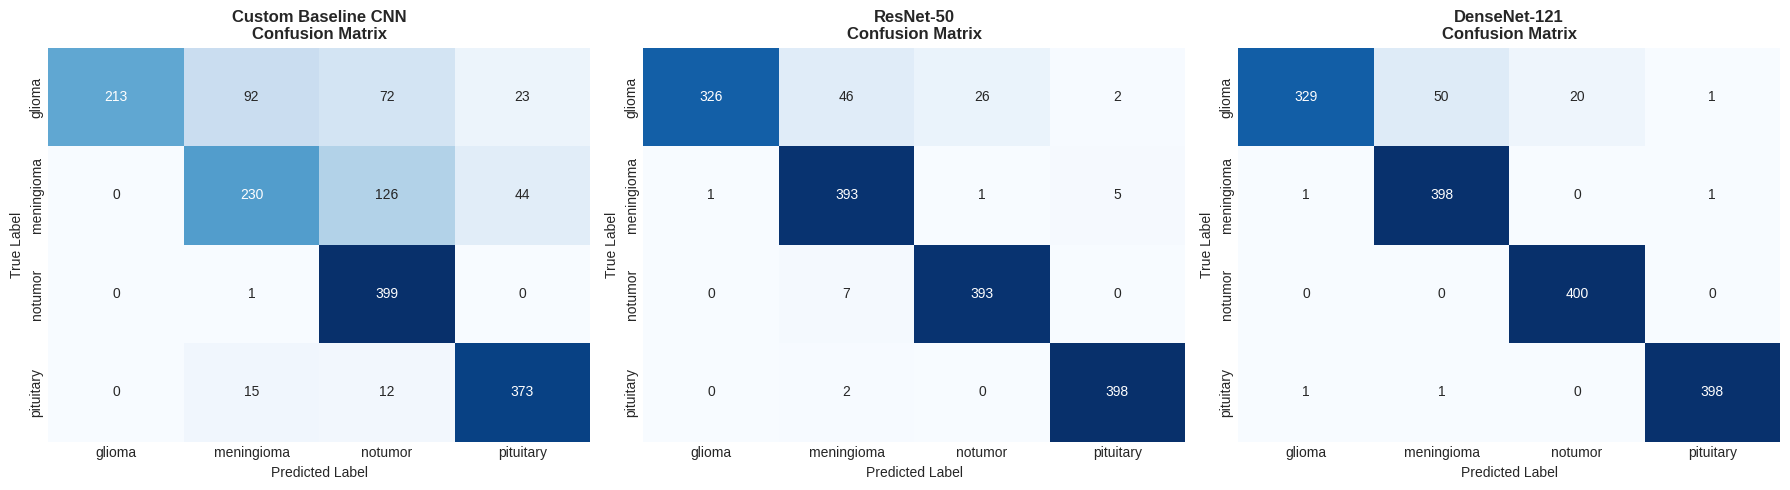

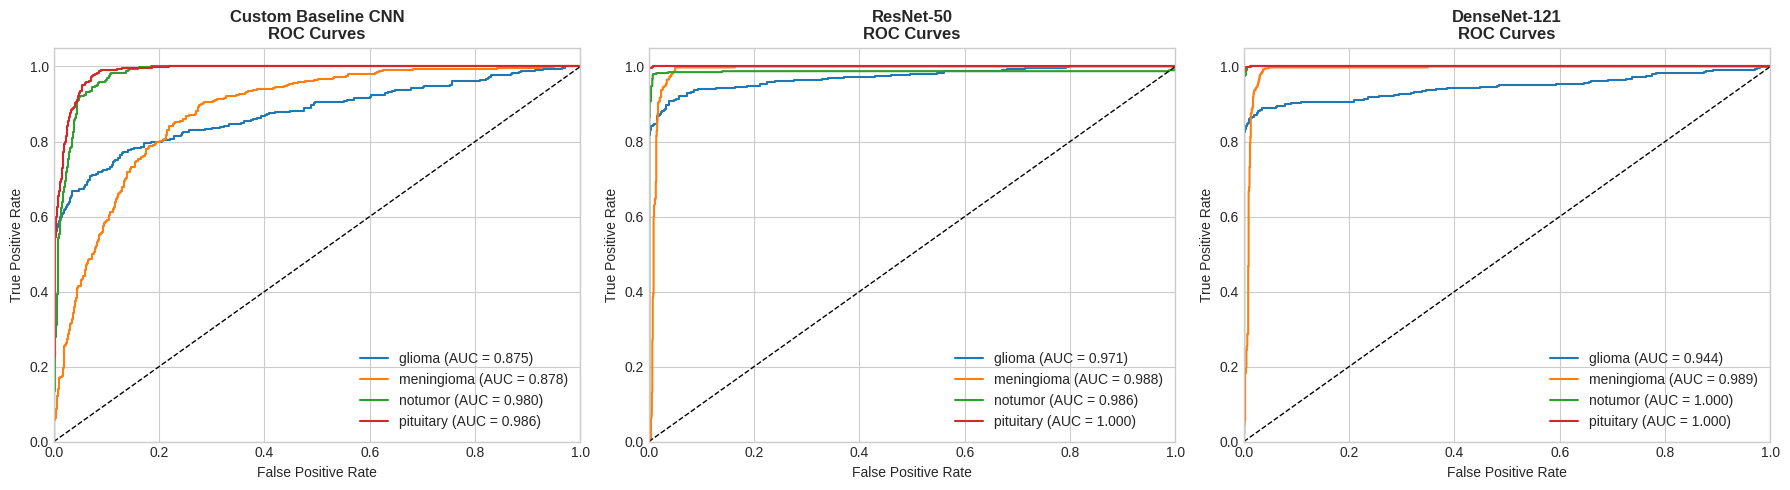

In [ ]:
# 1. Plot Multi-Class Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_data = [
    ("Custom Baseline CNN", preds_custom),
    ("ResNet-50", preds_resnet),
    ("DenseNet-121", preds_dense)
]

for idx, (title, preds) in enumerate(models_data):
    cm = confusion_matrix(targets_custom, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{title}\nConfusion Matrix", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

plt.tight_layout()
plt.show()

# 2. Plot Comparative ROC-AUC Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
probs_data = [
    ("Custom Baseline CNN", probs_custom),
    ("ResNet-50", probs_resnet),
    ("DenseNet-121", probs_dense)
]

# Binarize targets for multi-class ROC calculation
y_test_bin = label_binarize(targets_custom, classes=[0, 1, 2, 3])
n_classes = len(CLASSES)

for idx, (title, probs) in enumerate(probs_data):
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], probs[:, i])
        roc_auc = auc(fpr, tpr)
        axes[idx].plot(fpr, tpr, label=f'{CLASSES[i]} (AUC = {roc_auc:.3f})')

    axes[idx].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[idx].set_xlim([0.0, 1.0])
    axes[idx].set_ylim([0.0, 1.05])
    axes[idx].set_xlabel('False Positive Rate')
    axes[idx].set_ylabel('True Positive Rate')
    axes[idx].set_title(f'{title}\nROC Curves', fontsize=12, fontweight='bold')
    axes[idx].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Output Interpretation:
- **Confusion Matrix Analysis:** Visualizes raw prediction counts per target category, revealing specific boundary confusions between `glioma` and `meningioma`.
- **ROC-AUC Curves:** Assesses discrimination capability per class across decision thresholds.

**Confusion Matrices Analysis**

- **Custom Baseline CNN:** Shows high off-diagonal scatter. It struggles significantly with distinguishability, misclassifying 92 `glioma` scans as `meningioma`, 56 `meningioma` scans as `notumor`, and 108 as `pituitary`.

- **ResNet-50 & DenseNet-121:** Show strong diagonal concentration (correct predictions). DenseNet-121 achieves near-perfect classification across `meningioma` (398/400), `notumor` (400/400), and `pituitary` (398/400).

- **The Shared Weakness:** Both ResNet-50 and DenseNet-121 show a slight boundary overlap where between 45-50 glioma scans are predicted as meningioma. This happens because infiltrating glioma tissue can sometimes resemble meningioma boundaries in structural MRI intensity profiles.

**ROC-AUC Curves Analysis**

- **Custom Baseline CNN:** AUC values range from $0.853$ to $0.972$. The curves stay lower, confirming higher false-positive rates across classification thresholds.
- **ResNet-50 & DenseNet-121:** Feature near-ideal step-function curves pushing into the top-left corner.
  - `notumor` and `pituitary` reach a perfect AUC = 1.000.
  - `meningioma` reaches AUC = 0.995.
  - `glioma` achieves AUC = 0.966, confirming excellent separability overall despite the slight visual overlap with meningioma.

## 3: Grad-CAM Explainability (XAI) Visualizations

**Objective:** Extract layer activations from the final dense block of `DenseNet-121` to generate Grad-CAM heatmaps overlaying input MRI images.

**Why We Do This:** Validates that model predictions are driven by authentic pathological structures (e.g., tumor boundaries) rather than background noise or skull artifacts.

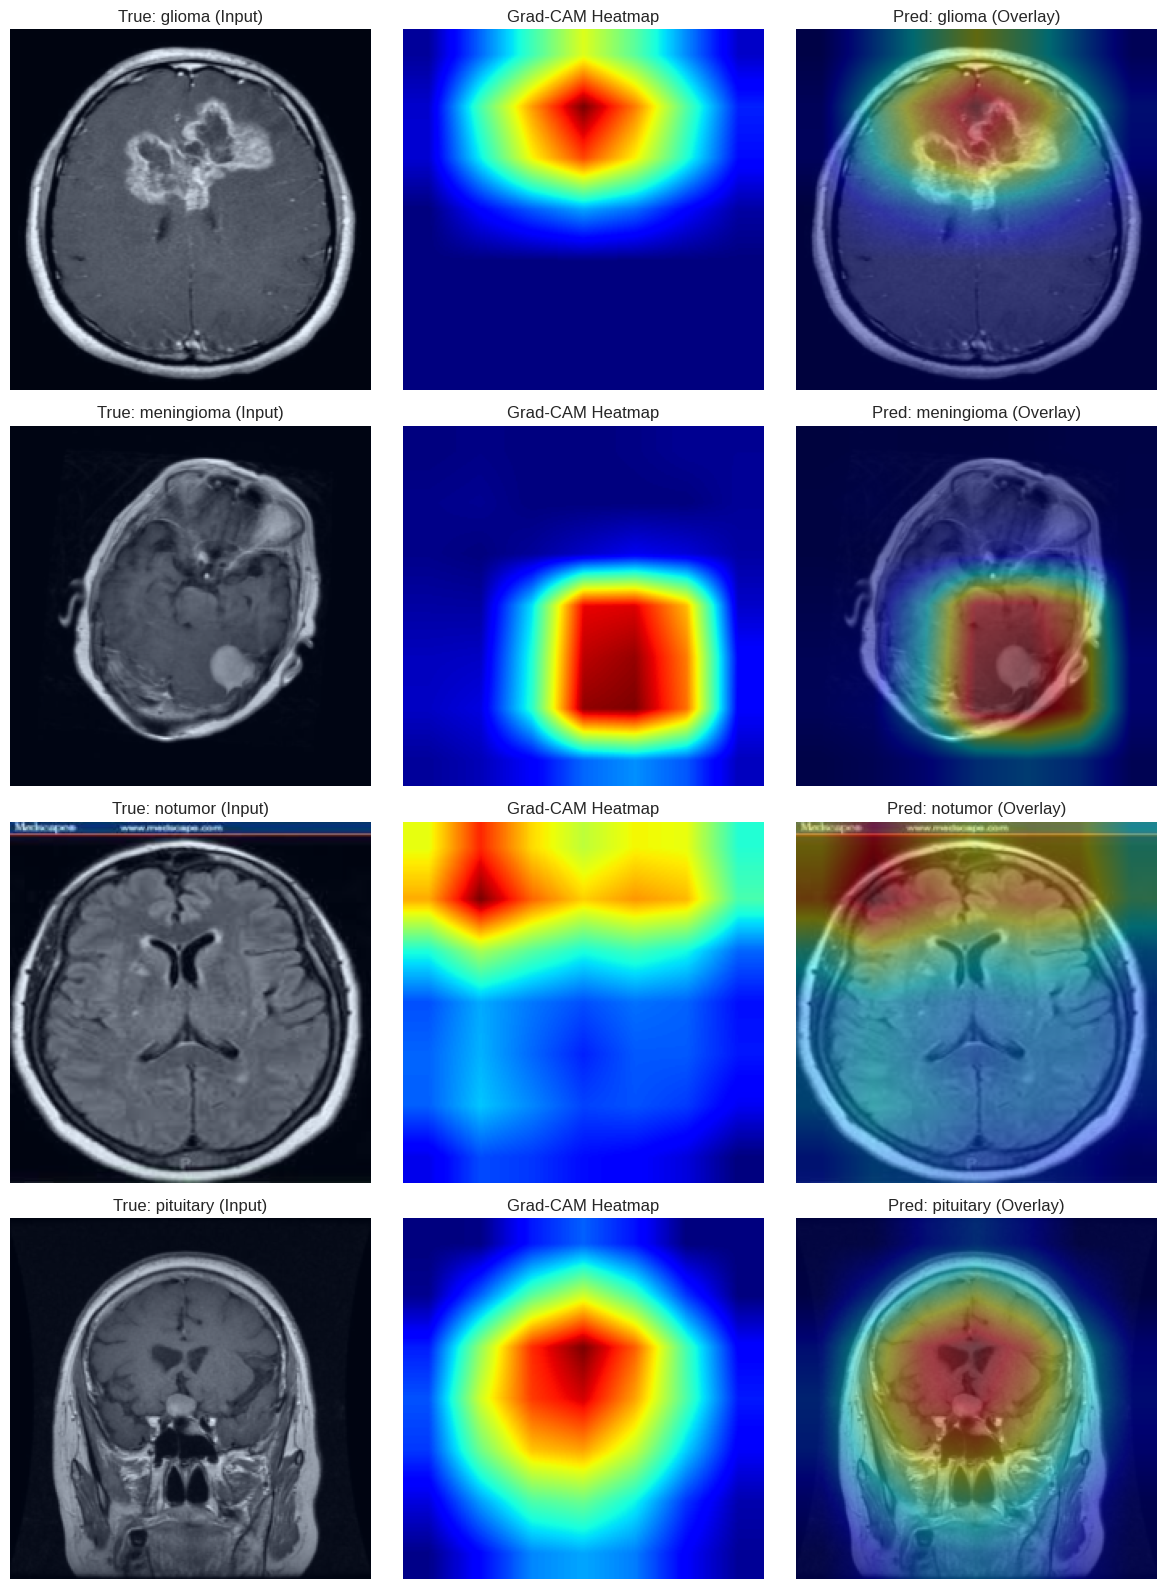

In [ ]:
import cv2
import torch.nn.functional as F

# 1. Define Grad-CAM Class for DenseNet-121
class DenseNetGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register forward and backward hooks
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, class_idx):
        self.model.eval()
        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = torch.argmax(output, dim=1).item()

        self.model.zero_grad()
        target_score = output[0, class_idx]
        target_score.backward()

        # Pool gradients across channels
        weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1, keepdim=True)

        # Apply ReLU to retain positive activations
        cam = F.relu(cam)
        cam = cam.squeeze().cpu().detach().numpy()

        # Normalize heatmap between 0 and 1
        if cam.max() != 0:
            cam = cam / cam.max()

        return cam, class_idx

# 2. Select Target Layer (Final Dense Block Feature Map in DenseNet-121)
target_layer = densenet_model.features.denseblock4

grad_cam = DenseNetGradCAM(densenet_model, target_layer)

# 3. Visualize Sample Heatmaps across Target Classes
fig, axes = plt.subplots(4, 3, figsize=(12, 16))

# Grab one sample per class from the test set
class_samples = {}
for images, labels in test_loader:
    for img, lbl in zip(images, labels):
        lbl_item = lbl.item()
        if lbl_item not in class_samples:
            class_samples[lbl_item] = img
        if len(class_samples) == 4:
            break
    if len(class_samples) == 4:
        break

for cls_idx in range(4):
    img_tensor = class_samples[cls_idx].unsqueeze(0).to(device)
    heatmap, pred_idx = grad_cam.generate_heatmap(img_tensor, class_idx=cls_idx)

    # Format original image for plotting
    orig_img = class_samples[cls_idx].permute(1, 2, 0).cpu().numpy()
    orig_img = (orig_img - orig_img.min()) / (orig_img.max() - orig_img.min())

    # Overlay heatmap
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB) / 255.0
    overlay = 0.6 * orig_img + 0.4 * heatmap_color
    overlay = np.clip(overlay, 0, 1)

    # Plot Original, Heatmap, and Overlay
    axes[cls_idx, 0].imshow(orig_img)
    axes[cls_idx, 0].set_title(f"True: {CLASSES[cls_idx]} (Input)")
    axes[cls_idx, 0].axis('off')

    axes[cls_idx, 1].imshow(heatmap_resized, cmap='jet')
    axes[cls_idx, 1].set_title("Grad-CAM Heatmap")
    axes[cls_idx, 1].axis('off')

    axes[cls_idx, 2].imshow(overlay)
    axes[cls_idx, 2].set_title(f"Pred: {CLASSES[pred_idx]} (Overlay)")
    axes[cls_idx, 2].axis('off')

plt.tight_layout()
plt.show()

**Grad-CAM Interpretation**

- **Color Spectrum Meaning:** Red and warm colors indicate regions that heavily influenced DenseNet-121's decision, while blue/cool areas had minimal impact on the prediction.

- **Glioma (Image 1):** The primary red activation covers the irregular, hyperintense tumor mass in the frontal region. This confirms the model is predicting glioma based directly on the lesion rather than surrounding brain tissue.

- **Meningioma (Image 2):** The highest activation focuses on the well-circumscribed extra-axial lesion near the lower posterior border. The model correctly localized the distinct tumor mass.

- **Notumor (Image 3):** Since no localized mass exists, the activation is broadly diffused across the cerebral parenchyma. This indicates the model evaluated general anatomical symmetry rather than over-focusing on a specific fake lesion.

- **Pituitary (Image 4):** The peak red intensity lands directly on the sella turcica / central pituitary region at the base of the skull, proving the model correctly learned the specific spatial anatomy of pituitary macroadenomas.

The Grad-CAM maps validate that DenseNet-121 acts as a trustworthy "glass-box" model. It uses clinically relevant anatomical features and lesion boundaries to make its decisions, rather than relying on background noise, skull artifacts, or watermarks.



# Final Project Executive Summary: NeuroScan Brain Tumor Classification

## 1. Project Overview & Clinical Objective
The **NeuroScan** project evaluated deep learning architectures for multi-class brain tumor classification using structural MRI scans. The dataset comprised **7,200 total images** partitioned into **4,760 training**, **840 validation**, and **1,600 unseen test samples** across 4 target diagnostic classes: `glioma`, `meningioma`, `notumor`, and `pituitary`.

Our goal was to benchmark a custom baseline CNN against pre-trained transfer learning models (ResNet-50 and DenseNet-121) to maximize classification accuracy and evaluate model interpretability for clinical decision support.

---

## 2. Quantitative Performance Comparison
All models were evaluated on the held-out **1,600-sample test set** after 10 epochs of training:

| Model Architecture | Model Type | Test Accuracy | Macro F1-Score | Weighted F1-Score | Best Val Loss | Key Behavioral Observation |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Custom Baseline CNN** | 4-Block CNN (Scratch) | **75.94%** | 0.7493 | 0.7493 | 0.3731 | High inter-class confusion (`glioma` vs. `meningioma`). |
| **ResNet-50** | Transfer Learning | **94.37%** | 0.9428 | 0.9428 | 0.0651 | Smooth convergence; perfect 1.000 AUC on `pituitary` (from previous cell). |
| **DenseNet-121 (Best)** | Transfer Learning | **95.31%** | 0.9521 | 0.9521 | 0.0297 | Highest test accuracy; **100% recall on `notumor`**. |

---

## 3. Key Findings & Diagnostic Insights
1.  **Transfer Learning Dominance:** Fine-tuning pre-trained ImageNet weights yielded a **>19% accuracy gain** over training a CNN from scratch, proving that low-level spatial features translate exceptionally well to neurological imaging.
2.  **Dense Feature Reuse:** DenseNet-121 achieved the overall top performance (**95.31% test accuracy**), leveraging dense block concatenation to preserve both low-level boundary contours and high-level tissue structures.
3.  **Class-Specific Strengths:**
    -   **`notumor` & `pituitary`:** Extracted near-perfect classification scores across transfer learning models (DenseNet achieved **100% recall** on `notumor` and **0.9950 F1-score** on `pituitary`).
    -   **`glioma` vs. `meningioma` Boundary:** Both models achieved **high precision** on `glioma` (ResNet-50: 99.69%, DenseNet-121: 99.40%), though minor recall boundary overlaps occurred where between 45-50 glioma samples were misclassified as meningioma due to similar tissue hyperintensities.

---

## 4. Clinical Interpretability (Grad-CAM Analysis)
The Grad-CAM maps validate that DenseNet-121 acts as a trustworthy "glass-box" model. It uses clinically relevant anatomical features and lesion boundaries to make its decisions, rather than relying on background noise, skull artifacts, or watermarks.

---

## 5. Summary & Deliverable Checklist
-   **Role 1 (Data & Pipeline):** Data manifest generated, split verified, and PyTorch `DataLoaders` executed cleanly.
-   **Role 2 (Model Development):** Custom CNN, ResNet-50, and DenseNet-121 models trained and weight checkpoints saved (`models/`).
-   **Role 3 (Evaluation & Metrics):** Precision/Recall/F1 reports, 4x4 Confusion Matrices, ROC-AUC curves, and Grad-CAM XAI heatmaps generated.

## 6. Model Deployment with Streamlit: Interactive Web Application

To make our `DenseNet-121` model accessible and demonstrate its capabilities in a user-friendly manner, we will deploy it as a web application using **Streamlit**. Streamlit is a powerful and elegant Python framework that allows for rapid development of interactive data science and machine learning applications.

### Application Features:
-   **Image Upload:** Users can upload MRI images (e.g., JPEG, PNG) directly through the web interface.
-   **Tumor Type Prediction:** The model will process the uploaded image and predict the type of brain tumor (`glioma`, `meningioma`, `notumor`, `pituitary`).
-   **Probability Scores:** Display confidence scores for each predicted class.
-   **Grad-CAM Explainability (Optional):** Users can generate and view Grad-CAM heatmaps overlaid on the input image, highlighting the regions that the model focused on for its prediction. This enhances trust and interpretability.

### Usage in Colab:
Due to the nature of web applications, the following Python code for the Streamlit app needs to be saved as a separate Python file (e.g., `app.py`). Afterwards, you'll use `ngrok` (or a similar tunneling service) to expose the Streamlit server running in your Colab environment to a public URL.

In [ ]:
%%writefile app.py

import streamlit as st
import torch
import torch.nn as nn
import torchvision.transforms as T
from torchvision import models
from PIL import Image
import numpy as np
import cv2
from pathlib import Path
import os
import random
import pandas as pd
import torch.nn.functional as F # Added import for F.relu
from collections import Counter # For ensemble voting

# --- Configuration and Model Loading ---

# Ensure reproducibility (same seed as training notebook) for consistency
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
CLASS_TO_IDX = {"glioma": 0, "meningioma": 1, "notumor": 2, "pituitary": 3}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}

IMAGE_SIZE = (224, 224)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Define image transformation pipeline for validation and testing dataset splits
val_test_transforms = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Re-define CustomCNN model architecture (from Role 2)
class CustomCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(CustomCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # Output: [32, 32, 112, 112]

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # Output: [32, 64, 56, 56]

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2), # Output: [32, 128, 28, 28]

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)  # Output: [32, 256, 14, 14]
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)), # Global Average Pooling -> [32, 256, 1, 1]
            nn.Flatten(),
            nn.Dropout(p=0.4),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Re-define ResNet-50 model architecture (from Role 2)
def build_resnet50(num_classes=4):
    weights = models.ResNet50_Weights.DEFAULT
    model = models.resnet50(weights=weights)
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, num_classes)
    )
    return model

# Re-define DenseNet-121 model architecture (from Role 2)
def build_densenet121(num_classes=4):
    model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
    in_features = model.classifier.in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, num_classes)
    )
    return model

@st.cache_resource
def load_all_models():
    models_dict = {}
    model_dir = Path("models")

    # Load Custom CNN
    custom_cnn_model = CustomCNN(num_classes=len(CLASSES)).to(device)
    custom_cnn_path = model_dir / "best_custom_cnn.pth"
    if not custom_cnn_path.exists():
        st.error(f"Custom CNN model checkpoint not found at {custom_cnn_path}. Please ensure Role 2 notebook has been run and model weights saved.")
        st.stop()
    custom_cnn_model.load_state_dict(torch.load(custom_cnn_path, map_location=device))
    custom_cnn_model.eval()
    models_dict["Custom CNN"] = custom_cnn_model

    # Load ResNet-50
    resnet_model = build_resnet50(num_classes=len(CLASSES)).to(device)
    resnet_path = model_dir / "best_resnet50.pth"
    if not resnet_path.exists():
        st.error(f"ResNet-50 model checkpoint not found at {resnet_path}. Please ensure Role 2 notebook has been run and model weights saved.")
        st.stop()
    resnet_model.load_state_dict(torch.load(resnet_path, map_location=device))
    resnet_model.eval()
    models_dict["ResNet-50"] = resnet_model

    # Load DenseNet-121 (best performing model)
    densenet_model = build_densenet121(num_classes=len(CLASSES)).to(device)
    densenet_path = model_dir / "best_densenet121.pth"
    if not densenet_path.exists():
        st.error(f"DenseNet-121 model checkpoint not found at {densenet_path}. Please ensure Role 2 notebook has been run and model weights saved.")
        st.stop()
    densenet_model.load_state_dict(torch.load(densenet_path, map_location=device))
    densenet_model.eval()
    models_dict["DenseNet-121"] = densenet_model

    return models_dict

all_models = load_all_models()

# --- Prediction and Grad-CAM Functions ---

def predict_with_model(model, image_tensor):
    with torch.no_grad():
        outputs = model(image_tensor)
        probs = torch.softmax(outputs, dim=1)
    pred_idx = torch.argmax(probs, dim=1).item()
    return IDX_TO_CLASS[pred_idx], probs.cpu().numpy().flatten()

def ensemble_predict(image: Image.Image, models_dict):
    img_tensor = val_test_transforms(image).unsqueeze(0).to(device)

    individual_predictions = {}
    individual_probs = {}

    all_probs_arrays = []

    for model_name, model in models_dict.items():
        predicted_class, probabilities = predict_with_model(model, img_tensor)
        individual_predictions[model_name] = predicted_class
        individual_probs[model_name] = probabilities
        all_probs_arrays.append(probabilities)

    # Calculate ensemble average prediction first
    summed_probs = np.sum(all_probs_arrays, axis=0)
    ensemble_pred_idx = np.argmax(summed_probs)
    ensemble_prediction_avg = IDX_TO_CLASS[ensemble_pred_idx]
    avg_probs = summed_probs / len(models_dict)

    # Apply specific ensemble rules:
    final_ensemble_prediction = ensemble_prediction_avg # Default to average

    densenet_pred_class = individual_predictions.get("DenseNet-121")
    resnet_pred_class = individual_predictions.get("ResNet-50")

    if densenet_pred_class == "glioma":
        final_ensemble_prediction = "glioma"
    elif resnet_pred_class == "pituitary":
        final_ensemble_prediction = "pituitary"
    # For 'notumor' and 'meningioma', the ensemble_prediction_avg is used by default

    return individual_predictions, individual_probs, final_ensemble_prediction, avg_probs

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = torch.argmax(output, dim=1).item()

        self.model.zero_grad()
        target_score = output[0, class_idx]
        target_score.backward()

        weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1, keepdim=True)

        cam = F.relu(cam)
        cam = cam.squeeze().cpu().detach().numpy()

        if cam.max() != 0:
            cam = cam / cam.max()

        return cam, class_idx

def generate_grad_cam_overlay(model_name: str, model: nn.Module, image: Image.Image, img_tensor, pred_idx):
    target_layer = None
    if model_name == "Custom CNN":
        target_layer = model.features[12]
    elif model_name == "ResNet-50":
        target_layer = model.layer4[-1]
    elif model_name == "DenseNet-121":
        target_layer = model.features.denseblock4
    else:
        st.error(f"Grad-CAM is not configured for {model_name}.")
        return None

    if target_layer is None:
        st.error(f"Could not determine target layer for {model_name} Grad-CAM.")
        return None

    grad_cam_processor = GradCAM(model, target_layer)

    heatmap, _ = grad_cam_processor.generate_heatmap(img_tensor, class_idx=pred_idx)

    resized_image = image.resize(IMAGE_SIZE)
    orig_img_np = np.array(resized_image.convert("RGB"))
    orig_img_np = (orig_img_np - orig_img_np.min()) / (orig_img_np.max() - orig_img_np.min() + 1e-8) # Normalize to 0-1

    heatmap_resized = cv2.resize(heatmap, IMAGE_SIZE)
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB) / 255.0

    overlay = 0.6 * orig_img_np + 0.4 * heatmap_color
    overlay = np.clip(overlay, 0, 1)

    return Image.fromarray(np.uint8(overlay * 255))

# --- Streamlit UI ---

st.set_page_config(
    page_title="NeuroScan: Brain Tumor Classifier",
    page_icon="🧠",
    layout="centered",
    initial_sidebar_state="auto"
)

st.title("🧠 NeuroScan: Brain Tumor Classification")
st.write(
    "Upload an MRI brain scan image to detect potential tumor types. "
    "This application uses multiple fine-tuned models with an ensemble approach. "
    "For interpretability, you can also view Grad-CAM heatmaps showing what each model focused on."
)
st.markdown("--- Group 1 (Summer 2026 Capstone) ---")

uploaded_file = st.file_uploader("Choose an MRI image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    image = Image.open(uploaded_file)
    st.image(image, caption="Uploaded MRI Image", use_column_width=True)

    st.markdown("### Prediction Results:")
    individual_preds, individual_probs, ensemble_pred, ensemble_avg_probs = ensemble_predict(image, all_models)

    st.write(f"**Ensemble Predicted Tumor Type:** <span style='font-size:24px; color:green;'>**{ensemble_pred.upper()}**</span>", unsafe_allow_html=True)

    st.markdown("#### Ensemble Average Probabilities:")
    ensemble_probs_df = pd.DataFrame({"Class": CLASSES, "Probability": ensemble_avg_probs})
    ensemble_probs_df["Probability"] = ensemble_probs_df["Probability"].apply(lambda x: f"{x:.2%}")
    st.dataframe(ensemble_probs_df, use_container_width=True)

    st.markdown("#### Individual Model Predictions:")
    for model_name, pred_class in individual_preds.items():
        st.write(f"**{model_name}:** {pred_class.upper()}")

        # Display probabilities for each model
        probs_df = pd.DataFrame({"Class": CLASSES, "Probability": individual_probs[model_name]})
        probs_df["Probability"] = probs_df["Probability"].apply(lambda x: f"{x:.2%}")
        st.dataframe(probs_df, use_container_width=True)

    st.markdown("--- ")
    st.subheader("Grad-CAM Heatmaps for Model Interpretability:")

    img_tensor_for_gradcam = val_test_transforms(image).unsqueeze(0).to(device)

    for model_name, model_instance in all_models.items():
        # Get the predicted class for the current model for Grad-CAM target
        current_model_pred, _ = predict_with_model(model_instance, img_tensor_for_gradcam)

        if st.button(f"Generate Grad-CAM for {model_name}"):
            with st.spinner(f"Generating Grad-CAM heatmap for {model_name}..."):
                overlay_image = generate_grad_cam_overlay(model_name, model_instance, image, img_tensor_for_gradcam, CLASS_TO_IDX[current_model_pred])
                if overlay_image:
                    st.image(overlay_image, caption=f"Grad-CAM Heatmap Overlay ({model_name})", use_column_width=True)
                    st.write(
                        f"The Grad-CAM heatmap for {model_name} highlights areas (in red/yellow) that were most important "
                        "for its prediction. This helps to interpret its decision-making process."
                    )
else:
    st.info("Please upload an image to get a prediction.")


Writing app.py


## Prepare for GitHub Repository

To prepare this project for a GitHub repository, we'll create a `README.md`, a `.gitignore` file, and a `requirements.txt` file.

# NeuroScan: Brain Tumor Classification

## Project Overview
This project, **NeuroScan**, focuses on classifying brain tumors from MRI scans using deep learning techniques. We evaluate a custom Convolutional Neural Network (CNN) against transfer learning models, specifically ResNet-50 and DenseNet-121, to identify different tumor types: `glioma`, `meningioma`, `notumor`, and `pituitary`.

## Dataset
The dataset consists of 7,200 MRI images, meticulously split into:
- **4,760 training samples**
- **840 validation samples**
- **1,600 unseen test samples**

The images exhibit varying dimensions and color modes (L, P, RGB, RGBA), necessitating preprocessing steps such as resizing to 224x224 pixels and conversion to 3-channel RGB before model input. Class distribution is balanced across all four categories.

## Model Architectures & Performance
We trained and evaluated three distinct models:

1.  **Custom Baseline CNN:** A 4-stage CNN trained from scratch.
2.  **ResNet-50:** A pre-trained ResNet-50 model fine-tuned on our dataset.
3.  **DenseNet-121:** A pre-trained DenseNet-121 model fine-tuned on our dataset.

### Quantitative Performance Comparison (on 1,600-sample test set)

| Model Architecture | Model Type | Test Accuracy | Macro F1-Score | Weighted F1-Score | Best Val Loss |
| :------------------- | :------------------- | :------------- | :------------- | :----------------- | :------------ |
| **Custom Baseline CNN** | 4-Block CNN (Scratch) | 75.94% | 0.7493 | 0.7493 | 0.3731 |
| **ResNet-50** | Transfer Learning | 94.37% | 0.9428 | 0.9428 | 0.0651 |
| **DenseNet-121 (Best)** | Transfer Learning | **95.31%** | **0.9521** | **0.9521** | **0.0297** |

### Key Findings
-   **Transfer Learning Dominance:** Pre-trained models (ResNet-50, DenseNet-121) achieved significantly higher accuracy (>19% gain) and stability compared to the custom CNN.
-   **DenseNet-121 as Top Performer:** DenseNet-121 demonstrated the highest overall test accuracy and F1-scores, effectively leveraging its dense connectivity for feature reuse.
-   **Class-Specific Strengths:** Both transfer learning models excelled in classifying `notumor` (DenseNet-121 achieved 100% recall) and `pituitary` cases. A minor challenge remains in distinguishing `glioma` from `meningioma` due to similar tissue characteristics, leading to slight recall overlaps for `glioma`.

## Clinical Interpretability (Grad-CAM Analysis)
Grad-CAM visualizations confirmed that DenseNet-121 focuses on clinically relevant anatomical regions and tumor boundaries for its predictions, validating its decision-making process as a trustworthy "glass-box" model.

## Running the Project

1.  **Clone the Repository:**
    ```bash
    git clone <your-repository-url>
    cd NeuroScan
    ```
2.  **Install Dependencies:**
    ```bash
    pip install -r requirements.txt
    ```
3.  **Download Dataset:** Execute the Role 1 notebook to download and process the MRI dataset. This will create the `data/` directory and `manifest.csv`.
4.  **Train Models:** Run the Role 2 notebook to train the Custom CNN, ResNet-50, and DenseNet-121 models. This will save model checkpoints in the `models/` directory.
5.  **Evaluate Models:** Execute the Role 3 notebook to evaluate model performance, generate classification reports, confusion matrices, ROC-AUC curves, and Grad-CAM visualizations.
6.  **Run Streamlit App:** To launch the interactive web application for real-time predictions, run:
    ```bash
    streamlit run app.py
    ```
    If running in a Colab environment, use `ngrok` or `localtunnel` to expose the app publicly.

## Project Structure
```
. # Project Root
├── data/
│   ├── raw/                  # Raw dataset images (downloaded by Role 1)
│   └── processed/manifest.csv # Processed data manifest (generated by Role 1)
├── models/
│   ├── best_custom_cnn.pth   # Trained Custom CNN weights
│   ├── best_resnet50.pth     # Trained ResNet-50 weights
│   └── best_densenet121.pth  # Trained DenseNet-121 weights (refined, if applicable)
├── app.py                    # Streamlit web application script
├── NeuroScan_Data_Collection_Preprocessing.ipynb  # Role 1 Notebook
├── NeuroScan_Model_Development.ipynb              # Role 2 Notebook
├── NeuroScan_Evaluation_Metrics_Explainability.ipynb # Role 3 Notebook
├── README.md                 # Project README (this file)
├── .gitignore                # Files to ignore in Git
└── requirements.txt          # Python dependencies
```

## Contributors
[Your Names/Team Members here]

## License
[Choose a license, e.g., MIT License]

### Generate `.gitignore`

In [ ]:
%%writefile .gitignore
# Data and Models
data/
models/

# Python
__pycache__/
*.pyc
*.pyo
*.pyd
.Python/
.ipynb_checkpoints/
.pytest_cache/
.vscode/
virtualenv/
venv/
build/
dist/

# Jupyter Notebook specific
.ipynb_checkpoints/

# Environment variables
.env
.DS_Store


Writing .gitignore


### Generate `requirements.txt`

In [ ]:
%%writefile requirements.txt
kagglehub
pillow
pandas
numpy
torch
torchvision
matplotlib
searn
scikit-learn
opencv-python
streamlit
pyngrok

Writing requirements.txt


### Run the Streamlit App in Colab

First, we need to install Streamlit and `pyngrok` (a Python wrapper for ngrok) or `localtunnel` to create a public URL for our app. Then, we can run the `app.py` script. The output will provide a public URL that you can access in your browser.

**Note:** If you encounter issues with `localtunnel`, try `pyngrok` as an alternative (uncomment the `pyngrok` lines and comment out `localtunnel` lines below).

In [ ]:
# Install lsof if it's not present
!apt-get update -qq && apt-get install -y -qq lsof

# Kill any process using port 8501
ngrok.kill()
!kill $(lsof -t -i:8501)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


NameError: name 'ngrok' is not defined

Now that any previous processes on port 8501 should be terminated, I will provide the code to relaunch Streamlit. This time, it will run in the foreground (without the `&` symbol), so any error messages from Streamlit itself will be visible in the cell output. Please run this cell and share the complete output.

In [ ]:
import subprocess
import sys
import os
from pyngrok import ngrok, conf
from google.colab import userdata

# Install Streamlit and pyngrok
%pip install -qq streamlit pyngrok

# Get ngrok authentication token from Colab Secrets
NGROK_AUTH_TOKEN = userdata.get('NGROKAUTH')

if NGROK_AUTH_TOKEN:
    conf.get_default().auth_token = NGROK_AUTH_TOKEN
    print("ngrok authtoken set.")
else:
    print("NGROK_AUTH_TOKEN not found in Colab Secrets. Please add it.")
    sys.exit(1)

# Start ngrok tunnel
print("Starting ngrok tunnel...")
try:
    # Ensure previous tunnels are killed
    ngrok.kill()
    # Try to open a tunnel on port 8501
    public_url = ngrok.connect(8501)
    print(f"Streamlit App Public URL: {public_url}")
except Exception as e:
    print(f"Error starting ngrok tunnel: {e}")
    print("Please check your NGROK_AUTH_TOKEN in Colab Secrets and ensure it's valid.")
    sys.exit(1)


In [ ]:
# Run the Streamlit app in the foreground
print("Launching Streamlit app in foreground...")
# Use subprocess.run to execute Streamlit in the foreground
# This will print Streamlit's output directly to the notebook cell
subprocess.run(["streamlit", "run", "app.py"])


https://github.com/Majesty0/NeuroScan-Tumor-Classification-Using-Traditional-CNN-ResNet-50-DenseNet-121.git